# GAIA — Prévision de l'humidité du sol à 7 jours (modèle entraîné)

**Objectif :** apprendre, à partir de données réelles de Tunisie, à prédire **l'humidité du sol dans la zone des racines (7–28 cm) pour chacun des 7 prochains jours**, puis en déduire quand irriguer.

**Couverture :** 26 sites, les 24 gouvernorats de Tunisie, de janvier 2020 jusqu'à hier. Le notebook télécharge seulement les jours qui manquent.

**Dataset :** [Open-Meteo](https://open-meteo.com/), modèle **ECMWF IFS** (analyses du centre européen, ~9 km). Gratuit, sans inscription, au jour le jour, pour n'importe quel point.
- C'est la source que le mode par défaut de l'archive Open-Meteo sert **depuis 2017** (avant, c'était ERA5-Land : on l'a vérifié en comparant les deux séries). On commence en 2020 pour n'avoir **qu'une seule source** dans tout le jeu de données.
- **En direct, la même source** vient de l'API de prévision d'Open-Meteo (`models=ecmwf_ifs`) : mêmes valeurs à 0,000 près sur les jours communs, et **disponible jusqu'à hier, sans retard de publication**.

| Variable | Rôle |
|---|---|
| Humidité du sol 0–7, 7–28, 28–100 cm (m³/m³) | **cible** (7–28 cm) et entrées |
| ET0 FAO, pluie, températures, rayonnement, vent | entrées |
| Latitude, longitude, altitude, saison | entrées |

**Modèle :** LightGBM (gradient boosting), un modèle par horizon, de J+1 à **J+8**. Il prédit **la variation** de l'humidité par rapport au dernier état connu. Pourquoi J+8 : le dernier jour complet est hier ; pour couvrir aujourd'hui et les 7 jours suivants, il faut prévoir jusqu'à 8 jours après.

**Évaluation honnête :**
- entraînement 2020–2023, validation 2024, **test 2025 → aujourd'hui** (années jamais vues, les plus récentes) ;
- 4 sites **jamais vus** à l'entraînement (test géographique) ;
- comparaison avec la **persistance** (« dans h jours, l'humidité sera la même qu'aujourd'hui »).

> ⚠️ **Limites à annoncer :** l'humidité ECMWF IFS est une *analyse de modèle* (~9 km), pas une mesure de terrain, et elle ne connaît pas la culture de la parcelle. Pendant l'entraînement, la météo des 7 jours suivants est la météo *observée* (prévision parfaite) ; en usage réel ce sera une *prévision*, donc l'erreur sera un peu plus grande.

In [1]:
import time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import lightgbm as lgb
import matplotlib.pyplot as plt

DATA_DIR = Path("data");    DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

START = "2020-01-01"
END = (pd.Timestamp.today().normalize() - pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # hier : dernier jour complet
FIN_ENTRAIN, ANNEE_VALID, DEBUT_TEST = 2023, 2024, 2025
print("Période :", START, "→", END)
HORIZONS = range(1, 9)         # J+1 … J+8 (voir l'introduction)
HORIZONS_PLAN = range(1, 8)    # le plan d'irrigation couvre 7 jours
CIBLE = "sm_7_28"   # humidité du sol 7–28 cm, zone des racines
plt.rcParams["figure.figsize"] = (11, 4)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
JOURS = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]

Période : 2020-01-01 → 2026-11-20


## 1. Les sites : 26 points agricoles couvrant les 24 gouvernorats
Du Nord céréalier aux oasis du Sud, en passant par le Sahel des oliviers et le pays des jessour (Tataouine). Chaque point est placé dans une zone agricole du gouvernorat, un peu à l'intérieur des terres pour que la case du modèle soit bien sur la terre. Quatre sites (un par grande zone) sont **gardés de côté** pour tester le modèle sur des lieux qu'il n'a jamais vus.

In [2]:
SITES = [
    # id,            nom,                         lat,    lon,   zone,            test géographique
    ("beja",        "Béja",                       36.73,  9.18, "Nord",           False),
    ("jendouba",    "Jendouba",                   36.50,  8.78, "Nord",           False),
    ("bousalem",    "Bou Salem",                  36.61,  8.97, "Nord",           True),
    ("kef",         "Le Kef",                     36.17,  8.70, "Nord-Ouest",     False),
    ("siliana",     "Siliana",                    36.08,  9.37, "Nord-Ouest",     False),
    ("zaghouan",    "Zaghouan",                   36.40, 10.14, "Nord-Est",       False),
    ("mateur",      "Mateur",                     37.04,  9.66, "Nord",           False),
    ("capbon",      "Menzel Bouzelfa (Cap Bon)",  36.68, 10.58, "Nord-Est",       False),
    ("kairouan",    "Kairouan",                   35.68, 10.10, "Centre",         False),
    ("sbeitla",     "Sbeitla",                    35.23,  9.13, "Centre-Ouest",   True),
    ("sidibouzid",  "Sidi Bouzid",                35.04,  9.48, "Centre",         False),
    ("kasserine",   "Kasserine",                  35.17,  8.83, "Centre-Ouest",   False),
    ("sfax",        "Agareb (Sfax)",              34.74, 10.52, "Sahel",          False),
    ("msaken",      "Msaken (Sahel)",             35.73, 10.58, "Sahel",          True),
    ("gafsa",       "Gafsa",                      34.42,  8.78, "Sud-Ouest",      False),
    ("medenine",    "Médenine",                   33.35, 10.50, "Sud-Est",        False),
    ("kebili",      "Kébili",                     33.70,  8.97, "Sud (oasis)",    True),
    ("tozeur",      "Tozeur",                     33.92,  8.13, "Sud (oasis)",    False),
    ("tunis",       "Tunis (Sijoumi)",            36.78, 10.08, "Grand Tunis",    False),
    ("ariana",      "Kalâat el-Andalous (Ariana)",37.02, 10.08, "Grand Tunis",    False),
    ("benarous",    "Mornag (Ben Arous)",         36.68, 10.29, "Grand Tunis",    False),
    ("manouba",     "Tebourba (Manouba)",         36.83,  9.84, "Nord (Medjerda)",False),
    ("monastir",    "Jemmal (Monastir)",          35.62, 10.76, "Sahel",          False),
    ("mahdia",      "El Jem (Mahdia)",            35.30, 10.71, "Sahel",          False),
    ("gabes",       "Chenini (oasis de Gabès)",   33.87, 10.06, "Sud-Est (oasis littorale)", False),
    ("tataouine",   "Tataouine (jessour)",        32.93, 10.45, "Sud-Est",        False),
]
SITES = pd.DataFrame(SITES, columns=["id", "nom", "lat", "lon", "zone", "test_geo"])
SITES

,id,nom,lat,lon,zone,test_geo
0,beja,Béja,36.73,9.18,Nord,False
1,jendouba,Jendouba,36.50,8.78,Nord,False
2,bousalem,Bou Salem,36.61,8.97,Nord,True
3,kef,Le Kef,36.17,8.70,Nord-Ouest,False
4,siliana,Siliana,36.08,9.37,Nord-Ouest,False
5,zaghouan,Zaghouan,36.40,10.14,Nord-Est,False
6,mateur,Mateur,37.04,9.66,Nord,False
7,capbon,Menzel Bouzelfa (Cap Bon),36.68,10.58,Nord-Est,False
8,kairouan,Kairouan,35.68,10.10,Centre,False
9,sbeitla,Sbeitla,35.23,9.13,Centre-Ouest,True


## 2. Téléchargement des données (mises en cache dans `data/`)
Un fichier par site (`data/<site>.csv`) : météo du jour et humidité du sol (moyenne des valeurs horaires). Relancer le notebook ne télécharge que les jours qui manquent :
- les jours anciens viennent de l'**archive** Open-Meteo (mode par défaut, ECMWF IFS depuis 2017) ;
- les 3 derniers mois viennent de l'**API de prévision** (`models=ecmwf_ifs`, mêmes valeurs), qui a un quota séparé et aucun retard.

In [3]:
URL = "https://archive-api.open-meteo.com/v1/archive"
DAILY  = ["et0_fao_evapotranspiration", "precipitation_sum", "temperature_2m_max",
          "temperature_2m_min", "shortwave_radiation_sum", "wind_speed_10m_max"]
HOURLY = ["soil_moisture_0_to_7cm", "soil_moisture_7_to_28cm", "soil_moisture_28_to_100cm"]
RENOMMER = {"et0_fao_evapotranspiration": "et0", "precipitation_sum": "pluie",
            "temperature_2m_max": "tmax", "temperature_2m_min": "tmin",
            "shortwave_radiation_sum": "rayonnement", "wind_speed_10m_max": "vent",
            "soil_moisture_0_to_7cm": "sm_0_7", "soil_moisture_7_to_28cm": "sm_7_28",
            "soil_moisture_28_to_100cm": "sm_28_100"}


FORECAST = "https://api.open-meteo.com/v1/forecast"


class LimiteJournaliere(Exception):
    pass


def appel_open_meteo(url, params):
    for essai in range(6):
        try:
            r = requests.get(url, params=params, timeout=300)
        except requests.RequestException as e:        # délai dépassé, coupure réseau : on réessaie
            print(f"  erreur réseau ({type(e).__name__}), nouvel essai dans 1 min", flush=True)
            time.sleep(60); continue
        if r.status_code == 429:
            if "Daily" in r.text:                      # quota du jour épuisé : inutile d'attendre
                raise LimiteJournaliere(r.json().get("reason"))
            print("  limite horaire de l'API atteinte, pause de 5 min", flush=True)
            time.sleep(300); continue
        r.raise_for_status()
        return r.json()
    raise RuntimeError("Open-Meteo ne répond pas, réessayez plus tard.")


def json_vers_table(j):
    h = pd.DataFrame(j["hourly"])
    h["date"] = pd.to_datetime(h.pop("time")).dt.floor("D")
    h = h.groupby("date").mean()                       # moyenne journalière de l'humidité du sol
    d = pd.DataFrame(j["daily"])
    d["date"] = pd.to_datetime(d.pop("time"))
    t = d.set_index("date").join(h).rename(columns=RENOMMER).reset_index()
    t["altitude"] = j["elevation"]
    return t


def telecharger_periode(lat, lon, debut, fin):
    # les 3 derniers mois : API de prévision (même modèle, quota séparé) ; avant : archive
    commun = dict(latitude=lat, longitude=lon, daily=",".join(DAILY), hourly=",".join(HOURLY), timezone="Africa/Tunis")
    if pd.Timestamp(debut) >= pd.Timestamp.today().normalize() - pd.Timedelta(days=88):
        t = json_vers_table(appel_open_meteo(FORECAST, commun | dict(models="ecmwf_ifs", past_days=92, forecast_days=1)))
        return t[(t.date >= debut) & (t.date <= fin)]
    return json_vers_table(appel_open_meteo(URL, commun | dict(start_date=debut, end_date=fin)))


def telecharger(site):
    # complète le cache jusqu'à END, par tranches de 2 ans, sans garder de jours incomplets
    f = DATA_DIR / f"{site.id}.csv"
    while True:
        df = pd.read_csv(f, parse_dates=["date"]) if f.exists() else None
        debut = pd.Timestamp(START) if df is None else df.date.max() + pd.Timedelta(days=1)
        if debut > pd.Timestamp(END):
            break
        fin = min(debut + pd.Timedelta(days=730), pd.Timestamp(END))
        try:
            nouveau = telecharger_periode(site.lat, site.lon, f"{debut:%Y-%m-%d}", f"{fin:%Y-%m-%d}")
        except LimiteJournaliere as e:
            print(f"  {site.id} : quota du jour épuisé ({e}) ; on garde les données en cache.")
            break
        complet = nouveau.dropna(subset=[CIBLE, "et0", "pluie"])
        if complet.empty:
            break
        nouveau = nouveau[nouveau.date <= complet.date.max()]
        df = nouveau if df is None else pd.concat([df, nouveau], ignore_index=True)
        df.to_csv(f, index=False)
        time.sleep(1)
        if complet.date.max() < fin:
            break
    df = pd.read_csv(f, parse_dates=["date"])
    return df[df.date >= START]


tables = []
for s in SITES.itertuples():
    df = telecharger(s)
    df["site"], df["lat"], df["lon"], df["test_geo"] = s.id, s.lat, s.lon, s.test_geo
    tables.append(df)
    print(f"{s.nom:28s} {len(df):5d} jours ({df.date.min():%Y-%m-%d} → {df.date.max():%Y-%m-%d})   "
          f"humidité 7–28 cm moyenne = {df.sm_7_28.mean():.3f} m³/m³")

data = pd.concat(tables, ignore_index=True)
manque = data.groupby("site")[CIBLE].apply(lambda x: x.isna().mean())
sans_sol = manque[manque > 0.5].index.tolist()
if sans_sol:
    print("⚠️ Sites sans données de sol (case du modèle sur la mer ?), retirés :", sans_sol)
    data = data[~data.site.isin(sans_sol)]
print("\nTotal :", len(data), "lignes,", data.site.nunique(), "sites")

Béja                          2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.333 m³/m³
Jendouba                      2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.197 m³/m³
Bou Salem                     2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.194 m³/m³
Le Kef                        2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.177 m³/m³
Siliana                       2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.209 m³/m³
Zaghouan                      2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.220 m³/m³
Mateur                        2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.210 m³/m³
Menzel Bouzelfa (Cap Bon)     2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.336 m³/m³
Kairouan                      2516 jours (2020-01-01 → 2026-11-20)   humidité 7–28 cm moyenne = 0.166 m³/m³
Sbeitla                     


Total : 65416 lignes, 26 sites


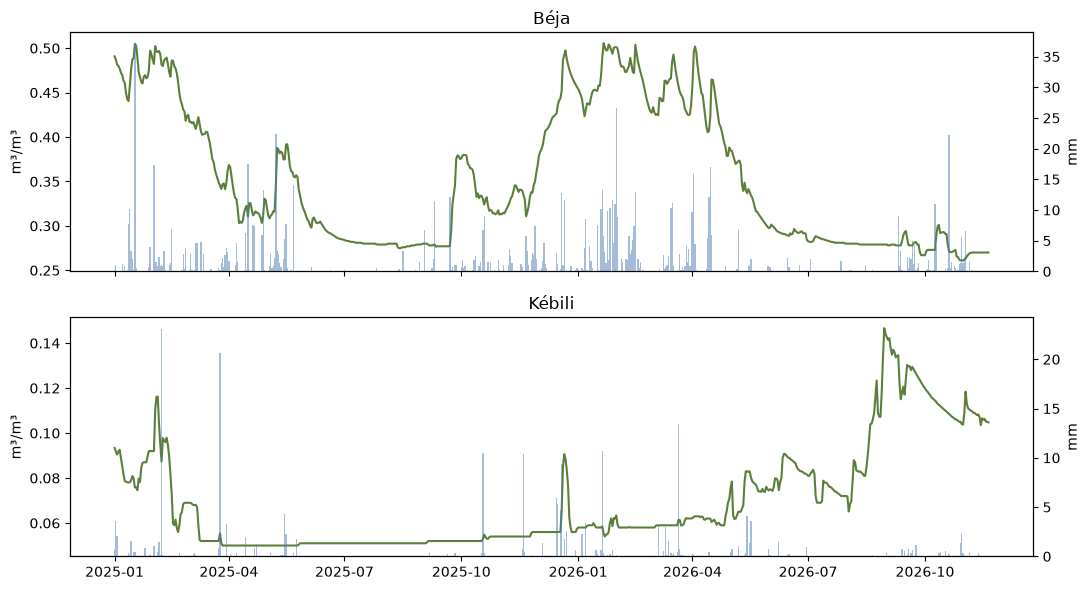

In [4]:
# Aperçu : un site du Nord et une oasis du Sud
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for a, sid in zip(ax, ["beja", "kebili"]):
    d = data[(data.site == sid) & (data.date.dt.year >= DEBUT_TEST)]
    a.plot(d.date, d.sm_7_28, color="#5b7f3a", label="Humidité du sol 7–28 cm")
    a2 = a.twinx(); a2.bar(d.date, d.pluie, color="#4a7bb7", alpha=.5, width=1, label="Pluie (mm)")
    a.set_title(SITES.set_index("id").nom[sid]); a.set_ylabel("m³/m³"); a2.set_ylabel("mm")
fig.tight_layout()

## 3. Construction des variables
Pour chaque jour *J* et chaque site :
- **état actuel du sol** : humidité aux 3 profondeurs, valeurs des jours précédents, variation de la veille ;
- **historique météo** : pluie cumulée sur 1, 3, 7, 30 jours ; ET0 cumulée sur 3, 7, 30 jours ;
- **météo des h prochains jours** (en usage réel : la prévision Open-Meteo) ;
- **lieu et saison** : latitude, longitude, altitude, jour de l'année (sinus / cosinus).

**Cible** pour l'horizon *h* : `humidité(J+h) − humidité(J)`.

In [5]:
def construire_variables(df):
    g = df.sort_values("date").copy()
    s = g[CIBLE]
    for l in [1, 2, 3, 7]:
        g[f"sm_lag{l}"] = s.shift(l)
    g["sm_diff1"] = s - s.shift(1)
    for w in [1, 3, 7, 30]:
        g[f"pluie_{w}j"] = g.pluie.rolling(w).sum()
    for w in [3, 7, 30]:
        g[f"et0_{w}j"] = g.et0.rolling(w).sum()
    doy = g.date.dt.day_of_year
    g["saison_sin"], g["saison_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    for h in HORIZONS:
        futur_pluie = pd.concat([g.pluie.shift(-k) for k in range(1, h + 1)], axis=1)
        futur_et0   = pd.concat([g.et0.shift(-k)   for k in range(1, h + 1)], axis=1)
        g[f"pluie_fut_{h}"]     = futur_pluie.sum(axis=1, min_count=h)
        g[f"pluie_max_fut_{h}"] = futur_pluie.max(axis=1)
        g[f"et0_fut_{h}"]       = futur_et0.sum(axis=1, min_count=h)
        g[f"cible_{h}"]         = s.shift(-h) - s
    return g


BASE = ["sm_0_7", "sm_7_28", "sm_28_100", "sm_lag1", "sm_lag2", "sm_lag3", "sm_lag7", "sm_diff1",
        "pluie", "et0", "tmax", "tmin", "rayonnement", "vent",
        "pluie_1j", "pluie_3j", "pluie_7j", "pluie_30j", "et0_3j", "et0_7j", "et0_30j",
        "lat", "lon", "altitude", "saison_sin", "saison_cos"]
variables = lambda h: BASE + [f"pluie_fut_{h}", f"pluie_max_fut_{h}", f"et0_fut_{h}"]

table = pd.concat([construire_variables(g) for _, g in data.groupby("site")], ignore_index=True)
annee = table.date.dt.year
ENTRAIN   = (~table.test_geo) & (annee <= FIN_ENTRAIN)
VALID     = (~table.test_geo) & (annee == ANNEE_VALID)
TEST_TEMP = (~table.test_geo) & (annee >= DEBUT_TEST)     # années jamais vues
TEST_GEO  = ( table.test_geo) & (annee >= DEBUT_TEST)     # lieux ET années jamais vus
print({k: int(v.sum()) for k, v in dict(entrainement=ENTRAIN, validation=VALID,
                                        test_annees=TEST_TEMP, test_lieux=TEST_GEO).items()})

{'entrainement': 32142, 'validation': 8052, 'test_annees': 15158, 'test_lieux': 2756}


## 4. Entraînement : un modèle LightGBM par horizon

In [6]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

modeles, resultats = {}, []
for h in HORIZONS:
    X, y = variables(h), f"cible_{h}"
    ok = table[X + [y]].notna().all(axis=1)
    tr, va = table[ENTRAIN & ok], table[VALID & ok]
    m = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.03, num_leaves=63, min_child_samples=40,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
    m.fit(tr[X], tr[y], eval_set=[(va[X], va[y])], callbacks=[lgb.early_stopping(100, verbose=False)])
    modeles[h] = m
    for nom, masque in [("années jamais vues", TEST_TEMP), ("lieux jamais vus", TEST_GEO)]:
        te = table[masque & ok]
        vrai = te[CIBLE] + te[y]                 # humidité réelle à J+h
        pred = te[CIBLE] + m.predict(te[X])      # humidité prédite à J+h
        r_mod, r_per = rmse(vrai, pred), rmse(vrai, te[CIBLE])
        resultats.append(dict(horizon=h, test=nom, rmse_modele=r_mod, rmse_persistance=r_per,
                              gain=1 - r_mod / r_per, arbres=m.best_iteration_))
    print(f"J+{h} entraîné ({m.best_iteration_} arbres)")

res = pd.DataFrame(resultats)
res.pivot(index="horizon", columns="test", values=["rmse_modele", "rmse_persistance", "gain"]).round(4)

J+1 entraîné (307 arbres)


J+2 entraîné (112 arbres)


J+3 entraîné (116 arbres)


J+4 entraîné (104 arbres)


J+5 entraîné (82 arbres)


J+6 entraîné (78 arbres)


J+7 entraîné (77 arbres)


J+8 entraîné (157 arbres)


rmse_modele                    rmse_persistance  \
test    années jamais vues lieux jamais vus années jamais vues   
horizon                                                          
1                   0.0056           0.0049             0.0070   
2                   0.0094           0.0083             0.0115   
3                   0.0118           0.0111             0.0148   
4                   0.0137           0.0131             0.0176   
5                   0.0152           0.0151             0.0200   
6                   0.0164           0.0166             0.0220   
7                   0.0175           0.0179             0.0237   
8                   0.0186           0.0188             0.0253   

                                       gain                   
test    lieux jamais vus années jamais vues lieux jamais vus  
horizon                                                       
1                 0.0070             0.2012           0.2982  
2                 0.0116             0.1844           0.2857  
3                 0.0152             0.2028           0.2722  
4                 0.0181             0.2199           0.2764  
5                 0.0207             0.2383           0.2703  
6                 0.0229             0.2533           0.2740  
7                 0.0248             0.2618           0.2761  
8                 0.0265             0.2653           0.2903

## 5. Résultats
**RMSE** = erreur moyenne en m³/m³ (plus c'est bas, mieux c'est). **Gain** = réduction de l'erreur par rapport à la persistance.

Réduction moyenne de l'erreur par rapport à la persistance :
  années jamais vues   23%
  lieux jamais vus     28%


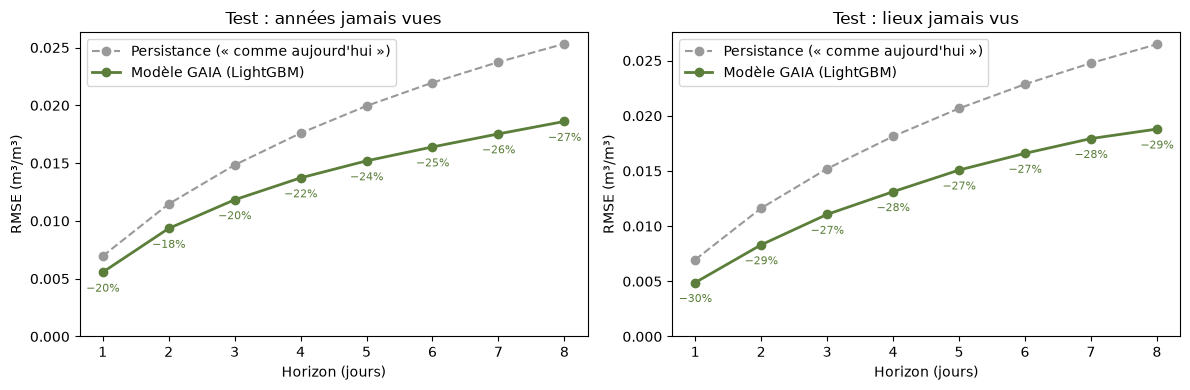

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, nom in zip(ax, ["années jamais vues", "lieux jamais vus"]):
    r = res[res.test == nom]
    a.plot(r.horizon, r.rmse_persistance, "o--", color="#999", label="Persistance (« comme aujourd'hui »)")
    a.plot(r.horizon, r.rmse_modele, "o-", color="#5b7f3a", lw=2, label="Modèle GAIA (LightGBM)")
    for _, row in r.iterrows():
        a.annotate(f"−{row.gain:.0%}", (row.horizon, row.rmse_modele), textcoords="offset points",
                   xytext=(0, -14), ha="center", fontsize=8, color="#5b7f3a")
    a.set_title(f"Test : {nom}"); a.set_xlabel("Horizon (jours)"); a.set_ylabel("RMSE (m³/m³)"); a.legend()
    a.set_ylim(bottom=0)
fig.tight_layout()

g = res.groupby("test").gain.mean()
print("Réduction moyenne de l'erreur par rapport à la persistance :")
for k, v in g.items():
    print(f"  {k:20s} {v:.0%}")

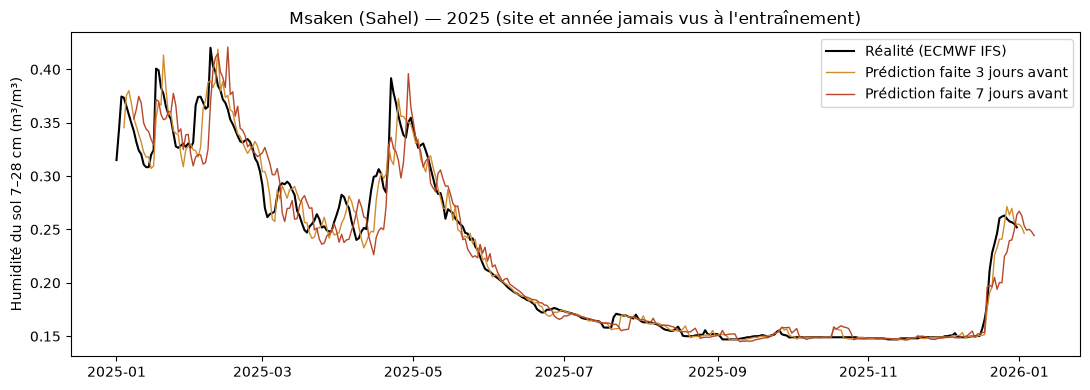

In [8]:
# Exemple sur un site jamais vu : prédiction à J+3 et J+7 comparée à la réalité
SITE_EX = "msaken"
d = table[(table.site == SITE_EX) & (table.date.dt.year == DEBUT_TEST)].copy()
fig, ax = plt.subplots()
ax.plot(d.date, d[CIBLE], color="black", lw=1.5, label="Réalité (ECMWF IFS)")
for h, c in [(3, "#d08c2e"), (7, "#b7472a")]:
    X = variables(h); ok = d[X].notna().all(axis=1)
    pred = d.loc[ok, CIBLE] + modeles[h].predict(d.loc[ok, X])
    ax.plot(d.loc[ok, "date"] + pd.Timedelta(days=h), pred, color=c, lw=1, label=f"Prédiction faite {h} jours avant")
ax.set_title(f"{SITES.set_index('id').nom[SITE_EX]} — {DEBUT_TEST} (site et année jamais vus à l'entraînement)")
ax.set_ylabel("Humidité du sol 7–28 cm (m³/m³)"); ax.legend()
fig.tight_layout()

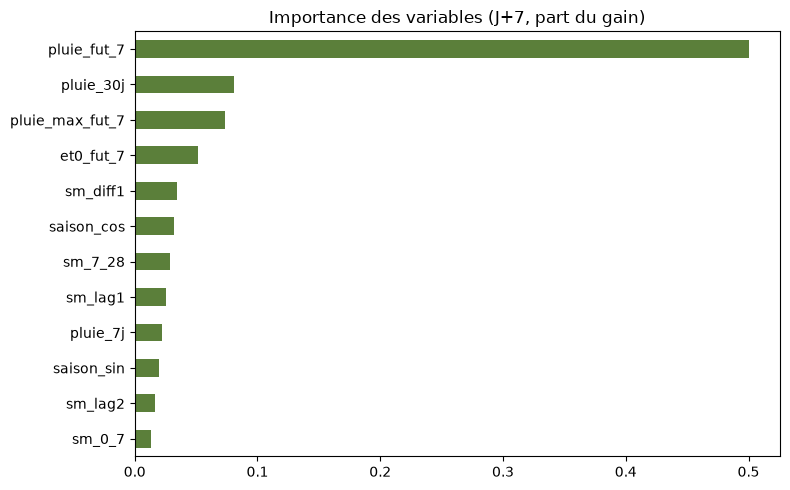

In [9]:
# Ce qui compte le plus pour prédire à J+7
h = 7
imp = pd.Series(modeles[h].booster_.feature_importance("gain"), index=variables(h))
imp = (imp / imp.sum()).sort_values()[-12:]
imp.plot.barh(color="#5b7f3a", figsize=(8, 5), title="Importance des variables (J+7, part du gain)")
plt.tight_layout()

## 6. Modèles finaux : réentraînés sur toutes les données jusqu'à hier, puis sauvegardés
Les scores ci-dessus viennent de modèles qui **n'ont jamais vu 2024–2026 ni les 4 sites de test** : c'est ce qui les rend honnêtes.
Pour l'usage réel, on garde les mêmes réglages (même nombre d'arbres) et on **réentraîne sur tout** : les 26 sites, de 2020 jusqu'au dernier jour dont on connaît la suite (hier − h jours).
Ce sont ces modèles finaux, les plus proches d'aujourd'hui, que le backend charge (`lightgbm.Booster(model_file=...)`) et que la section 8 utilise en direct.
Les sections 7, 9 et 10 continuent d'évaluer les modèles de test, pour ne pas tricher.

In [10]:
modeles_finaux = {}
for h, m in modeles.items():
    X, y = variables(h), f"cible_{h}"
    tout = table[table[X + [y]].notna().all(axis=1)]
    mf = lgb.LGBMRegressor(**{**m.get_params(), "n_estimators": m.best_iteration_})
    mf.fit(tout[X], tout[y])
    modeles_finaux[h] = mf
    mf.booster_.save_model(str(MODEL_DIR / f"humidite_sol_J{h}.txt"))
    print(f"J+{h} final : {len(tout)} lignes, {tout.site.nunique()} sites, {tout.date.min():%d/%m/%Y} → {tout.date.max():%d/%m/%Y}")
FIN_FINAL = table[table["cible_1"].notna()].date.max().strftime("%Y-%m-%d")
# seuils sec / humide de chaque site : 5e et 95e centiles de son humidité historique
seuils = data.groupby("site")[CIBLE].quantile([0.05, 0.95]).unstack()
meta = dict(cible=CIBLE, horizons=list(HORIZONS), variables={h: variables(h) for h in HORIZONS},
            source="Open-Meteo, modèle ECMWF IFS (archive et API de prévision)", periode=[START, data.date.max().strftime("%Y-%m-%d")],
            decoupage=dict(entrainement=f"{START[:4]}–{FIN_ENTRAIN}", validation=ANNEE_VALID, test=f"{DEBUT_TEST} →"),
            modele_final=dict(entraine_sur=f"{START} → {FIN_FINAL}", sites=int(table.site.nunique()),
                              note="scores mesurés avant, sur des modèles qui n'avaient vu ni 2024–2026 ni les sites de test"),
            resultats=res.round(5).to_dict("records"),
            seuils_sites={s: dict(sec=round(r[0.05], 4), humide=round(r[0.95], 4)) for s, r in seuils.iterrows()},
            sites=SITES[SITES.id.isin(data.site.unique())][["id", "nom", "lat", "lon", "zone"]].to_dict("records"))
# prédiction de référence : permet au backend de vérifier qu'il calcule exactement comme ce notebook
ref = table[(table.site == "msaken") & (table.date == "2023-06-18")]
meta["exemple"] = dict(site="msaken", date="2023-06-18",
                       predictions={h: float(ref[CIBLE].iloc[0] + modeles_finaux[h].predict(ref[variables(h)])[0]) for h in HORIZONS})
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
sorted(p.name for p in MODEL_DIR.iterdir())

J+1 final : 64636 lignes, 26 sites, 30/01/2020 → 19/11/2026


J+2 final : 64610 lignes, 26 sites, 30/01/2020 → 18/11/2026


J+3 final : 64584 lignes, 26 sites, 30/01/2020 → 17/11/2026


J+4 final : 64558 lignes, 26 sites, 30/01/2020 → 16/11/2026


J+5 final : 64532 lignes, 26 sites, 30/01/2020 → 15/11/2026


J+6 final : 64506 lignes, 26 sites, 30/01/2020 → 14/11/2026


J+7 final : 64480 lignes, 26 sites, 30/01/2020 → 13/11/2026


J+8 final : 64454 lignes, 26 sites, 30/01/2020 → 12/11/2026


['bascule_7j.txt',
 'bascule_meta.json',
 'humidite_sol_J1.txt',
 'humidite_sol_J2.txt',
 'humidite_sol_J3.txt',
 'humidite_sol_J4.txt',
 'humidite_sol_J5.txt',
 'humidite_sol_J6.txt',
 'humidite_sol_J7.txt',
 'humidite_sol_J8.txt',
 'meta.json',
 'pluie_efficace.txt',
 'pluie_efficace_meta.json']

## 7. De la prédiction à la décision d'irrigation
Pour rester honnête sans inventer de propriétés de sol, la **réserve** est exprimée par rapport à l'historique du site :
0 % = aussi sec que les 5 % des jours les plus secs, 100 % = aussi humide que les 5 % les plus humides.

**Hypothèse de démonstration** (à remplacer par les seuils de la culture, FAO-56) : *irriguer* quand la réserve prévue passe sous **30 %**, *bientôt* sous **35 %**.

In [11]:
SEUIL_IRRIGATION = 0.30
SEUIL_ALERTE = 0.35        # « bientôt » : la réserve approche du seuil

def reserve(theta, site_id):
    lo, hi = seuils.loc[site_id, 0.05], seuils.loc[site_id, 0.95]
    return float(np.clip((theta - lo) / (hi - lo), 0, 1))


def plan_7_jours(t, site_id, horizons=HORIZONS_PLAN, mods=None):
    # t : table de variables du site ; la dernière ligne = le dernier état connu du sol
    # mods : modèles de test par défaut (démonstration honnête) ; modeles_finaux en direct
    mods = mods or modeles
    jour = t.iloc[-1]
    lignes = []
    for h in horizons:
        theta = jour[CIBLE] + mods[h].predict(t.iloc[[-1]][variables(h)])[0]
        r = reserve(theta, site_id)
        d = jour.date + pd.Timedelta(days=h)
        lignes.append(dict(jour=f"{JOURS[d.weekday()]} {d:%d/%m}",
                           pluie_prevue_mm=round(jour[f"pluie_fut_{h}"] - (jour[f"pluie_fut_{h-1}"] if h > 1 else 0), 1),
                           humidite_prevue=round(theta, 3), reserve=f"{r:.0%}",
                           decision="💧 irriguer" if r < SEUIL_IRRIGATION else ("⚠️ bientôt" if r < SEUIL_ALERTE else "—")))
    return pd.DataFrame(lignes)


# Démonstration sur un site jamais vu, pendant les années de test, comparée à ce qui s'est réellement passé.
# On prend le premier jour où la réserve RÉELLE passe sous le seuil dans la semaine : c'est là que la décision compte.
site_id = "msaken"
d = table[(table.site == site_id) & (annee >= DEBUT_TEST)].reset_index(drop=True)
r_vraie = lambda col: (col - seuils.loc[site_id, 0.05]) / (seuils.loc[site_id, 0.95] - seuils.loc[site_id, 0.05])
candidats = d[(r_vraie(d[CIBLE]) >= SEUIL_ALERTE) & (r_vraie(d[CIBLE] + d["cible_5"]) < SEUIL_IRRIGATION)]
date = candidats.date.iloc[0] if len(candidats) else pd.Timestamp("2023-06-18")
t = table[(table.site == site_id) & (table.date <= date)]
plan = plan_7_jours(t, site_id)
reel = table[(table.site == site_id) & (table.date > date)].head(7)[CIBLE].round(3).values
plan["humidite_reelle"] = reel
plan["reserve_reelle"] = [f"{reserve(v, site_id):.0%}" for v in reel]
print(f"Plan pour {SITES.set_index('id').nom[site_id]} à partir du {date:%d/%m/%Y} "
      f"(réserve aujourd'hui : {reserve(t.iloc[-1][CIBLE], site_id):.0%})")
plan

Plan pour Msaken (Sahel) à partir du 18/06/2023 (réserve aujourd'hui : 32%)


,jour,pluie_prevue_mm,humidite_prevue,reserve,decision,humidite_reelle,reserve_reelle
0,lun 19/06,0.0,0.176,29%,💧 irriguer,0.175,28%
1,mar 20/06,0.0,0.172,27%,💧 irriguer,0.171,26%
2,mer 21/06,0.0,0.168,24%,💧 irriguer,0.170,26%
3,jeu 22/06,0.0,0.167,24%,💧 irriguer,0.168,25%
4,ven 23/06,0.0,0.167,24%,💧 irriguer,0.162,21%
5,sam 24/06,0.0,0.165,23%,💧 irriguer,0.161,21%
6,dim 25/06,0.0,0.164,23%,💧 irriguer,0.160,20%


## 8. Prévision réelle pour aujourd'hui et la semaine qui vient (nécessite internet)
Avec les **modèles finaux** (section 6), entraînés jusqu'à hier.
Tout vient de l'**API de prévision** d'Open-Meteo, modèle ECMWF IFS : l'état du sol jusqu'à hier, la météo observée, puis la météo prévue. Le modèle part d'hier (dernier jour complet) et couvre aujourd'hui + 7 jours. Changez `LAT`, `LON` pour votre parcelle.

In [12]:
LAT, LON = 35.73, 10.58      # Msaken, Sahel — mettez ici les coordonnées de la parcelle

try:
    auj = pd.Timestamp.today().normalize()
    j = appel_open_meteo(FORECAST, dict(latitude=LAT, longitude=LON, models="ecmwf_ifs", past_days=60, forecast_days=10,
                                        daily=",".join(DAILY), hourly=",".join(HOURLY), timezone="Africa/Tunis"))
    t = json_vers_table(j).assign(lat=LAT, lon=LON)
    etat = auj - pd.Timedelta(days=1)                            # hier : dernier jour complet
    t = construire_variables(t)
    t = t[t.date <= etat]
    site_proche = SITES.assign(d=(SITES.lat - LAT) ** 2 + (SITES.lon - LON) ** 2).sort_values("d").id.iloc[0]
    print(f"Dernier état du sol : {etat:%d/%m/%Y} (hier) ; ensuite, météo prévue (ECMWF IFS).")
    print(f"Seuils sec/humide empruntés au site d'entraînement le plus proche : {site_proche}")
    display(plan_7_jours(t, site_proche, range(1, 9), mods=modeles_finaux))     # modèles finaux, entraînés jusqu'à hier
except Exception as e:
    print("Prévision en direct indisponible :", e)

Dernier état du sol : 20/11/2026 (hier) ; ensuite, météo prévue (ECMWF IFS).
Seuils sec/humide empruntés au site d'entraînement le plus proche : msaken


,jour,pluie_prevue_mm,humidite_prevue,reserve,decision
0,sam 21/11,0.0,0.219,52%,—
1,dim 22/11,0.0,0.216,50%,—
2,lun 23/11,0.0,0.215,50%,—
3,mar 24/11,0.0,0.213,49%,—
4,mer 25/11,0.0,0.212,48%,—
5,jeu 26/11,6.0,0.214,49%,—
6,ven 27/11,3.6,0.216,51%,—
7,sam 28/11,0.0,0.219,52%,—


## 9. Évaluation complète : R², erreur en mm, décision « irriguer »
Chaque métrique est comparée à la **persistance** (« comme aujourd'hui »), sinon elle ne veut rien dire :
- **R² de l'humidité** : gonflé, car le sol change lentement ; la persistance a déjà un R² très élevé.
- **R² de la variation** : *le chiffre honnête*. Part des **changements** d'humidité que le modèle prévoit.
- **MAE / RMSE en mm d'eau** dans la couche 7–28 cm (210 mm d'épaisseur) ; **biais** = erreur systématique.
- **Décision « irriguer »** (réserve < 30 %) : exactitude, précision, rappel, F1.

1) QUALITÉ DE LA PRÉDICTION D'HUMIDITÉ


test,horizon,R² humidité,R² persistance,R² variation,MAE (mm),RMSE (mm),Biais (mm),Gain vs persistance
années jamais vues,J+1,0.997,0.995,0.362,0.56,1.17,-0.03,20%
années jamais vues,J+2,0.990,0.986,0.334,1.02,1.96,-0.01,18%
années jamais vues,J+3,0.985,0.976,0.364,1.37,2.48,-0.04,20%
années jamais vues,J+4,0.979,0.966,0.391,1.66,2.88,-0.04,22%
années jamais vues,J+5,0.975,0.956,0.419,1.90,3.19,-0.04,24%
années jamais vues,J+6,0.970,0.947,0.442,2.11,3.44,-0.08,25%
années jamais vues,J+7,0.966,0.938,0.454,2.30,3.68,-0.10,26%
années jamais vues,J+8,0.962,0.929,0.460,2.47,3.91,-0.23,27%
lieux jamais vus,J+1,0.997,0.993,0.507,0.54,1.03,-0.04,30%
lieux jamais vus,J+2,0.991,0.981,0.490,0.97,1.74,-0.07,29%



2) QUALITÉ DE LA DÉCISION « IRRIGUER » (réserve < 30 %)


test,horizon,jours « irriguer » réels,Exactitude,Précision,Rappel,F1,F1 persistance
années jamais vues,J+1,3739,98.8%,97.1%,97.9%,97.5%,97.4%
années jamais vues,J+2,3738,97.9%,95.0%,96.5%,95.8%,95.4%
années jamais vues,J+3,3737,97.3%,93.2%,96.0%,94.6%,93.8%
années jamais vues,J+4,3736,96.7%,91.8%,95.0%,93.4%,92.2%
années jamais vues,J+5,3735,96.1%,90.6%,93.8%,92.2%,90.9%
années jamais vues,J+6,3734,95.6%,89.5%,93.2%,91.3%,89.6%
années jamais vues,J+7,3733,95.2%,88.5%,92.6%,90.5%,88.5%
années jamais vues,J+8,3732,94.8%,87.3%,92.8%,90.0%,87.5%
lieux jamais vus,J+1,536,99.5%,99.1%,98.5%,98.8%,98.8%
lieux jamais vus,J+2,536,99.3%,98.5%,98.1%,98.3%,97.9%


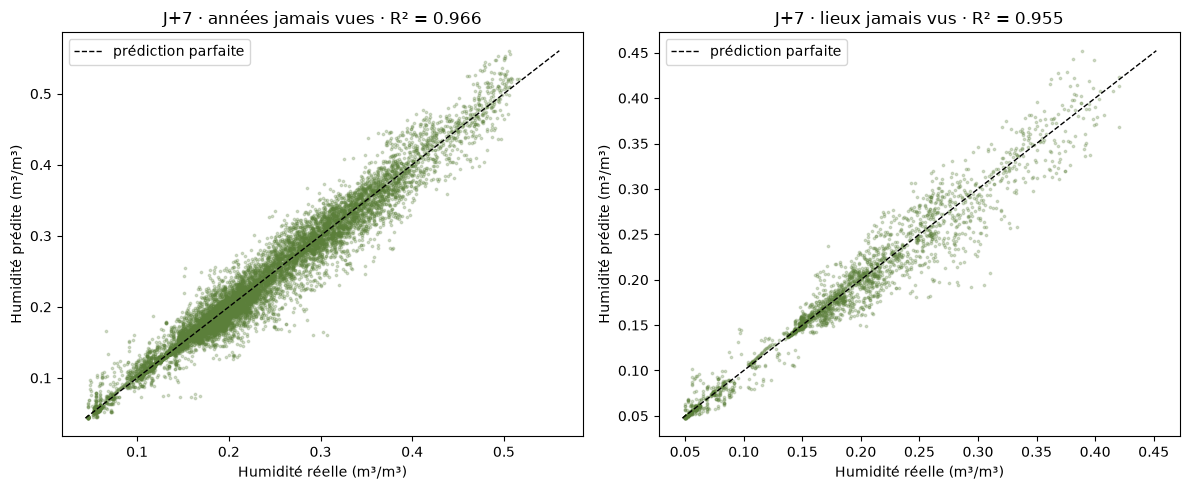


▶ ANNÉES JAMAIS VUES
  R² de l'humidité : 0.962 à 0.997 (persistance : 0.929 à 0.995)
  R² de la variation (ce qui va changer) : 0.36 à J+1, 0.45 à J+7
  Erreur moyenne : 0.6 mm d'eau à J+1, 2.3 mm à J+7
  Décision « irriguer » à J+7 : précision 89%, rappel 93%, F1 90% (persistance : F1 89%)

▶ LIEUX JAMAIS VUS
  R² de l'humidité : 0.951 à 0.997 (persistance : 0.902 à 0.993)
  R² de la variation (ce qui va changer) : 0.51 à J+1, 0.48 à J+7
  Erreur moyenne : 0.5 mm d'eau à J+1, 2.4 mm à J+7
  Décision « irriguer » à J+7 : précision 92%, rappel 95%, F1 93% (persistance : F1 95%)


In [13]:
# ==========================================================
# ÉVALUATION COMPLÈTE DU MODÈLE
# ==========================================================
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             precision_score, recall_score, f1_score, accuracy_score)

MM = 210   # couche 7–28 cm = 210 mm : 0,01 m³/m³ d'erreur = 2,1 mm d'eau

lignes, decisions, nuages = [], [], {}
for nom, masque in [("années jamais vues", TEST_TEMP), ("lieux jamais vus", TEST_GEO)]:
    for h in HORIZONS:
        X, y = variables(h), f"cible_{h}"
        te = table[masque & table[X + [y]].notna().all(axis=1)]
        auj = te[CIBLE].values
        vrai_var, pred_var = te[y].values, modeles[h].predict(te[X])
        vrai, pred = auj + vrai_var, auj + pred_var
        rmse_m = np.sqrt(mean_squared_error(vrai, pred))
        rmse_p = np.sqrt(mean_squared_error(vrai, auj))
        lignes.append({"test": nom, "horizon": f"J+{h}",
                       "R² humidité": r2_score(vrai, pred),
                       "R² persistance": r2_score(vrai, auj),
                       "R² variation": r2_score(vrai_var, pred_var),
                       "MAE (mm)": mean_absolute_error(vrai, pred) * MM,
                       "RMSE (mm)": rmse_m * MM,
                       "Biais (mm)": (pred - vrai).mean() * MM,
                       "Gain vs persistance": 1 - rmse_m / rmse_p})
        # la décision « irriguer » (réserve < 30 %) : le modèle l'annonce-t-il au bon moment ?
        lo = te.site.map(seuils[0.05]).values
        hi = te.site.map(seuils[0.95]).values
        sec_vrai = (vrai - lo) / (hi - lo) < SEUIL_IRRIGATION
        sec_pred = (pred - lo) / (hi - lo) < SEUIL_IRRIGATION
        sec_auj = (auj - lo) / (hi - lo) < SEUIL_IRRIGATION     # persistance : « comme aujourd'hui »
        decisions.append({"test": nom, "horizon": f"J+{h}",
                          "jours « irriguer » réels": int(sec_vrai.sum()),
                          "Exactitude": accuracy_score(sec_vrai, sec_pred),
                          "Précision": precision_score(sec_vrai, sec_pred, zero_division=0),
                          "Rappel": recall_score(sec_vrai, sec_pred, zero_division=0),
                          "F1": f1_score(sec_vrai, sec_pred, zero_division=0),
                          "F1 persistance": f1_score(sec_vrai, sec_auj, zero_division=0)})
        if h == 7:
            nuages[nom] = (vrai, pred)

metriques = pd.DataFrame(lignes)
print("1) QUALITÉ DE LA PRÉDICTION D'HUMIDITÉ")
display(metriques.style.format({"R² humidité": "{:.3f}", "R² persistance": "{:.3f}", "R² variation": "{:.3f}", "MAE (mm)": "{:.2f}",
                                "RMSE (mm)": "{:.2f}", "Biais (mm)": "{:+.2f}", "Gain vs persistance": "{:.0%}"})
        .hide(axis="index"))

print("\n2) QUALITÉ DE LA DÉCISION « IRRIGUER » (réserve < 30 %)")
display(pd.DataFrame(decisions).style.format({"Exactitude": "{:.1%}", "Précision": "{:.1%}",
                                              "Rappel": "{:.1%}", "F1": "{:.1%}", "F1 persistance": "{:.1%}"}).hide(axis="index"))

# 3) nuage de points : prédit vs réel à J+7
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (nom, (vrai, pred)) in zip(ax, nuages.items()):
    a.scatter(vrai, pred, s=3, alpha=.25, color="#5b7f3a")
    lim = [min(vrai.min(), pred.min()), max(vrai.max(), pred.max())]
    a.plot(lim, lim, "k--", lw=1, label="prédiction parfaite")
    a.set_title(f"J+7 · {nom} · R² = {r2_score(vrai, pred):.3f}")
    a.set_xlabel("Humidité réelle (m³/m³)"); a.set_ylabel("Humidité prédite (m³/m³)"); a.legend()
fig.tight_layout(); plt.show()

# 4) résumé en clair
for nom in ["années jamais vues", "lieux jamais vus"]:
    m = metriques[metriques.test == nom].set_index("horizon")
    d = pd.DataFrame(decisions)
    d = d[d.test == nom].set_index("horizon")
    print(f"\n▶ {nom.upper()}")
    print(f"  R² de l'humidité : {m['R² humidité'].min():.3f} à {m['R² humidité'].max():.3f} "
          f"(persistance : {m['R² persistance'].min():.3f} à {m['R² persistance'].max():.3f})")
    print(f"  R² de la variation (ce qui va changer) : {m.loc['J+1', 'R² variation']:.2f} à J+1, {m.loc['J+7', 'R² variation']:.2f} à J+7")
    print(f"  Erreur moyenne : {m.loc['J+1', 'MAE (mm)']:.1f} mm d'eau à J+1, {m.loc['J+7', 'MAE (mm)']:.1f} mm à J+7")
    print(f"  Décision « irriguer » à J+7 : précision {d.loc['J+7', 'Précision']:.0%}, rappel {d.loc['J+7', 'Rappel']:.0%}, "
          f"F1 {d.loc['J+7', 'F1']:.0%} (persistance : F1 {d.loc['J+7', 'F1 persistance']:.0%})")

## 10. Piste d'amélioration : les moments de bascule
La section 9 montre que la décision « irriguer » n'est qu'un peu meilleure que la persistance : un sol sec reste souvent sec des semaines, donc « comme aujourd'hui » a presque toujours raison. **La décision ne compte vraiment qu'au moment où la réserve passe sous le seuil** : c'est là qu'il faut prévenir l'agriculteur.

On isole donc ces moments. Parmi les jours où la réserve est **encore au-dessus de 30 %**, on se pose une seule question :
> **La réserve va-t-elle passer sous 30 % dans les 7 prochains jours, et quel jour ?**

Quatre méthodes, comparées sur les mêmes jours :
1. **Persistance** : « comme aujourd'hui », donc ne prévoit jamais de bascule.
2. **Tendance** : prolonge la pente des 3 derniers jours.
3. **Trajectoire du modèle** : les 7 modèles de régression ; bascule si une des 7 prévisions passe sous 30 %.
4. **Modèle dédié aux bascules** : un classifieur LightGBM entraîné uniquement sur ces jours, avec la réserve relative et sa pente comme variables, et un seuil de probabilité réglé sur 2024 (année de validation).

Pour éviter toute fuite d'information, les seuils sec/humide de chaque site sont ici calculés **sur les années d'entraînement seulement** (2020–2023).

In [14]:
# 10a. Les moments de bascule
seuils_ent = table[annee <= FIN_ENTRAIN].groupby("site")[CIBLE].quantile([0.05, 0.95]).unstack()
LO, HI = table.site.map(seuils_ent[0.05]), table.site.map(seuils_ent[0.95])

def rel(theta):
    # humidité → réserve relative au site (0 = sec, 1 = humide), même index que theta
    lo, hi = LO.loc[theta.index], HI.loc[theta.index]
    return (theta - lo) / (hi - lo)

table["reserve_auj"] = rel(table[CIBLE])
table["reserve_lag1"] = rel(table.sm_lag1)
table["reserve_lag3"] = rel(table.sm_lag3)
table["reserve_pente3"] = (table.reserve_auj - table.reserve_lag3) / 3

reserve_vraie = pd.concat({h: rel(table[CIBLE] + table[f"cible_{h}"]) for h in HORIZONS_PLAN}, axis=1)
sous_vrai = reserve_vraie < SEUIL_IRRIGATION
complet = reserve_vraie.notna().all(axis=1) & table[variables(7) + ["reserve_lag3"]].notna().all(axis=1)
POP = complet & (table.reserve_auj >= SEUIL_IRRIGATION)          # jours encore au-dessus du seuil
table["bascule_7j"] = sous_vrai.any(axis=1)
table["jour_bascule"] = sous_vrai.idxmax(axis=1).where(sous_vrai.any(axis=1))

for nom, m in [("entraînement", ENTRAIN), (f"validation {ANNEE_VALID}", VALID), ("test années", TEST_TEMP), ("test lieux", TEST_GEO)]:
    d = table[m & POP]
    print(f"{nom:16s} {len(d):6d} jours au-dessus du seuil, dont {int(d.bascule_7j.sum()):5d} bascules dans les 7 jours "
          f"({d.bascule_7j.mean():.1%})")

entraînement      17520 jours au-dessus du seuil, dont  1247 bascules dans les 7 jours (7.1%)
validation 2024    6040 jours au-dessus du seuil, dont   219 bascules dans les 7 jours (3.6%)
test années       12476 jours au-dessus du seuil, dont   409 bascules dans les 7 jours (3.3%)
test lieux         2348 jours au-dessus du seuil, dont    56 bascules dans les 7 jours (2.4%)


In [15]:
# 10b. Les méthodes simples : persistance, tendance, trajectoire des 7 modèles
def premier_jour(sous):
    # premier horizon où la réserve est sous le seuil, NaN s'il n'y en a pas
    return sous.idxmax(axis=1).where(sous.any(axis=1))

def trajectoire_modele(d):
    return pd.concat({h: rel(pd.Series(d[CIBLE].values + modeles[h].predict(d[variables(h)]), index=d.index))
                      for h in HORIZONS_PLAN}, axis=1)

def trajectoire_tendance(d):
    return pd.concat({h: d.reserve_auj + h * d.reserve_pente3 for h in HORIZONS_PLAN}, axis=1)

In [16]:
# 10c. Le modèle dédié aux bascules (classifieur LightGBM)
VAR_BASCULE = BASE + ["reserve_auj", "reserve_lag1", "reserve_lag3", "reserve_pente3",
                      "pluie_fut_3", "et0_fut_3", "pluie_fut_7", "pluie_max_fut_7", "et0_fut_7"]
tr, va = table[ENTRAIN & POP], table[VALID & POP]
# les bascules sont rares (~5 %) : on suit la précision moyenne (average precision) plutôt que l'exactitude,
# et c'est le seuil de probabilité réglé plus bas qui gère le déséquilibre
clf = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=60,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, verbose=-1)
clf.fit(tr[VAR_BASCULE], tr.bascule_7j, eval_set=[(va[VAR_BASCULE], va.bascule_7j)], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(200, verbose=False, first_metric_only=False)])

# seuil de probabilité réglé sur l'année de validation (jamais sur les années de test)
proba_va = clf.predict_proba(va[VAR_BASCULE])[:, 1]
grille = np.linspace(0.05, 0.95, 91)
SEUIL_PROBA = float(grille[np.argmax([f1_score(va.bascule_7j, proba_va >= s) for s in grille])])
print(f"Classifieur : {clf.best_iteration_} arbres, seuil de probabilité retenu = {SEUIL_PROBA:.2f}")

Classifieur : 94 arbres, seuil de probabilité retenu = 0.54


1) LE MODÈLE ANNONCE-T-IL LA BASCULE ? (sur les jours encore au-dessus de 30 %)


test,méthode,bascules réelles,bascules annoncées,Précision,Rappel,F1
années jamais vues,Persistance,409,0,0.0%,0.0%,0.0%
années jamais vues,Tendance (3 derniers jours),409,719,31.3%,55.0%,39.9%
années jamais vues,Trajectoire des 7 modèles,409,379,54.4%,50.4%,52.3%
années jamais vues,Modèle dédié aux bascules,409,338,57.7%,47.7%,52.2%
lieux jamais vus,Persistance,56,0,0.0%,0.0%,0.0%
lieux jamais vus,Tendance (3 derniers jours),56,70,22.9%,28.6%,25.4%
lieux jamais vus,Trajectoire des 7 modèles,56,34,64.7%,39.3%,48.9%
lieux jamais vus,Modèle dédié aux bascules,56,27,81.5%,39.3%,53.0%



2) ANNONCE-T-IL LE BON JOUR ? (bascules réelles bien détectées ; retard > 0 = annoncée trop tard)


test,méthode,bascules détectées,bon jour,à ±1 jour,écart moyen (jours),retard moyen (jours)
années jamais vues,Trajectoire des 7 modèles,206,32%,55%,1.60,+0.70
années jamais vues,Modèle dédié aux bascules,195,33%,57%,1.55,+0.83
lieux jamais vus,Trajectoire des 7 modèles,22,32%,64%,1.32,+0.77
lieux jamais vus,Modèle dédié aux bascules,22,27%,59%,1.45,+0.73


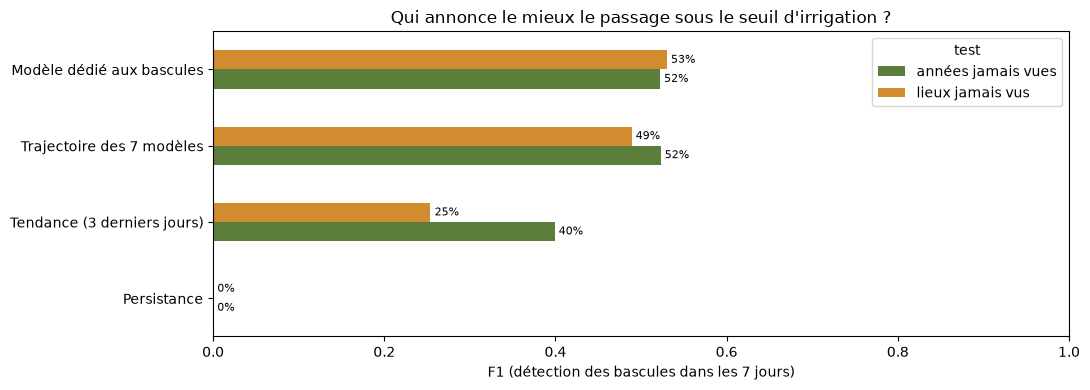

In [17]:
# 10d. Comparaison sur les années et les lieux jamais vus
resultats_bascule, timing = [], []
for nom, masque in [("années jamais vues", TEST_TEMP), ("lieux jamais vus", TEST_GEO)]:
    d = table[masque & POP]
    vrai, jour_vrai = d.bascule_7j.values, d.jour_bascule
    traj = trajectoire_modele(d)
    jour_traj = premier_jour(traj < SEUIL_IRRIGATION)
    # jour annoncé par le classifieur : premier jour sous le seuil sur la trajectoire, sinon le jour le plus sec
    jour_clf = jour_traj.fillna(traj.idxmin(axis=1))
    proba = clf.predict_proba(d[VAR_BASCULE])[:, 1]
    methodes = {
        "Persistance": (np.zeros(len(d), bool), None),
        "Tendance (3 derniers jours)": ((trajectoire_tendance(d) < SEUIL_IRRIGATION).any(axis=1).values, None),
        "Trajectoire des 7 modèles": (jour_traj.notna().values, jour_traj),
        "Modèle dédié aux bascules": (proba >= SEUIL_PROBA, jour_clf),
    }
    for meth, (pred, jour) in methodes.items():
        resultats_bascule.append({"test": nom, "méthode": meth, "bascules réelles": int(vrai.sum()),
                                  "bascules annoncées": int(pred.sum()),
                                  "Précision": precision_score(vrai, pred, zero_division=0),
                                  "Rappel": recall_score(vrai, pred, zero_division=0),
                                  "F1": f1_score(vrai, pred, zero_division=0)})
        if jour is not None:
            ok = vrai & pred                                    # bascules réelles bien détectées
            ecart = (jour[ok] - jour_vrai[ok]).values
            timing.append({"test": nom, "méthode": meth, "bascules détectées": int(ok.sum()),
                           "bon jour": np.mean(ecart == 0), "à ±1 jour": np.mean(np.abs(ecart) <= 1),
                           "écart moyen (jours)": np.mean(np.abs(ecart)), "retard moyen (jours)": np.mean(ecart)})

rb = pd.DataFrame(resultats_bascule)
print("1) LE MODÈLE ANNONCE-T-IL LA BASCULE ? (sur les jours encore au-dessus de 30 %)")
display(rb.style.format({"Précision": "{:.1%}", "Rappel": "{:.1%}", "F1": "{:.1%}"}).hide(axis="index"))
print("\n2) ANNONCE-T-IL LE BON JOUR ? (bascules réelles bien détectées ; retard > 0 = annoncée trop tard)")
display(pd.DataFrame(timing).style.format({"bon jour": "{:.0%}", "à ±1 jour": "{:.0%}", "écart moyen (jours)": "{:.2f}",
                                           "retard moyen (jours)": "{:+.2f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4))
piv = rb.pivot(index="méthode", columns="test", values="F1").loc[[m for m in methodes]]
piv.plot.barh(ax=ax, color=["#5b7f3a", "#d08c2e"])
ax.set_xlabel("F1 (détection des bascules dans les 7 jours)"); ax.set_xlim(0, 1); ax.set_ylabel("")
ax.set_title("Qui annonce le mieux le passage sous le seuil d'irrigation ?")
for c in ax.containers:
    ax.bar_label(c, fmt="{:.0%}", padding=3, fontsize=8)
fig.tight_layout(); plt.show()

In [18]:
# 10e. Sauvegarde du modèle dédié aux bascules
clf.booster_.save_model(str(MODEL_DIR / "bascule_7j.txt"))
(MODEL_DIR / "bascule_meta.json").write_text(json.dumps(dict(
    question="la réserve passe-t-elle sous le seuil dans les 7 prochains jours ? (jours où elle est encore au-dessus)",
    seuil_reserve=SEUIL_IRRIGATION, seuil_probabilite=SEUIL_PROBA, variables=VAR_BASCULE,
    seuils_sites_entrainement={s: dict(sec=round(r[0.05], 4), humide=round(r[0.95], 4)) for s, r in seuils_ent.iterrows()},
    resultats=rb.round(4).to_dict("records")), ensure_ascii=False, indent=1), encoding="utf-8")

for nom in ["années jamais vues", "lieux jamais vus"]:
    r = rb[rb.test == nom].set_index("méthode")
    print(f"▶ {nom} : F1 bascules — persistance {r.loc['Persistance', 'F1']:.0%}, "
          f"tendance {r.loc['Tendance (3 derniers jours)', 'F1']:.0%}, "
          f"trajectoire {r.loc['Trajectoire des 7 modèles', 'F1']:.0%}, "
          f"modèle dédié {r.loc['Modèle dédié aux bascules', 'F1']:.0%}")

▶ années jamais vues : F1 bascules — persistance 0%, tendance 40%, trajectoire 52%, modèle dédié 52%
▶ lieux jamais vus : F1 bascules — persistance 0%, tendance 25%, trajectoire 49%, modèle dédié 53%


## 11. Pluie efficace : ce qui reste vraiment dans le sol
Le calcul « Eau & énergie » de GAIA utilise aujourd'hui la **méthode USDA-SCS** (FAO CROPWAT) : une formule empirique des années 1970, **la même pour tous les sols**. Pour un mois à 30 mm de pluie, elle compte 28,6 mm comme « efficaces » (95 %), que le sol soit un sable du Sud ou une argile du Nord.

Ici, on **mesure dans les données** combien de chaque pluie reste réellement dans le sol, puis on apprend à le prévoir.

**Ce qu'on mesure, pour chaque épisode de pluie** (jours de pluie consécutifs ≥ 1 mm) :
- l'eau stockée dans le sol sur **0–100 cm** (3 couches : 0–7, 7–28, 28–100 cm), **la veille** de la pluie et **le lendemain** de la fin de la pluie ;
- on ajoute le **séchage qui aurait eu lieu de toute façon** pendant ces jours (perte moyenne d'un jour sec, pour ce site et ce mois, mesurée sur les années d'entraînement) ;
- **pluie efficace mesurée = gain du sol + séchage attendu**, bornée entre 0 et la pluie tombée. Le reste est parti en ruissellement ou en drainage profond.

**Le type de sol :** les données n'ont pas de colonne « texture ». On utilise la **signature hydrique du site** : niveau le plus sec et le plus humide de chaque couche (5ᵉ et 95ᵉ centiles, années d'entraînement). Un sable garde peu d'eau (niveaux bas et proches), une argile beaucoup ; c'est ce que le modèle ECMWF tire de sa propre carte des sols.

**Le modèle :** LightGBM, qui prédit les **mm de pluie efficace** de l'épisode à partir de la pluie (total, maximum journalier, durée), de l'humidité de départ à chaque profondeur, de la réserve relative, des pluies et de l'ET0 des jours précédents, de la chaleur, de la saison, de l'altitude et de la signature du sol.

Mêmes règles que plus haut : entraînement 2020–2023, validation 2024, **test 2025 → hier**, et les 4 **lieux jamais vus**.

In [19]:
# 11a. Épisodes de pluie et pluie efficace mesurée
COUCHES = {"sm_0_7": 70, "sm_7_28": 210, "sm_28_100": 720}      # épaisseur de chaque couche en mm

def stock_sol(d):
    return sum(d[c] * mm for c, mm in COUCHES.items())            # eau dans 0–100 cm, en mm

def episodes(d, seuil=1.0):
    d = d.sort_values("date").reset_index(drop=True)
    d["S"] = stock_sol(d)
    pluvieux = d.pluie >= seuil
    groupe = (pluvieux != pluvieux.shift()).cumsum()
    lignes = []
    for _, g in d[pluvieux].groupby(groupe[pluvieux]):
        i0, i1 = g.index[0], g.index[-1]
        if i0 < 30 or i1 + 1 >= len(d):
            continue
        avant, apres, hist = d.loc[i0 - 1], d.loc[i1 + 1], d.loc[i0 - 30:i0 - 1]
        lignes.append(dict(site=d.site.iloc[0], debut=g.date.iloc[0], jours=len(g),
                           pluie_evt=g.pluie.sum() + apres.pluie, pluie_max=g.pluie.max(), et0_evt=g.et0.sum() + apres.et0,
                           tmax=g.tmax.mean(), altitude=avant.altitude,
                           sm_0_7=avant.sm_0_7, sm_7_28=avant.sm_7_28, sm_28_100=avant.sm_28_100,
                           pluie_7j=hist.pluie.iloc[-7:].sum(), pluie_30j=hist.pluie.sum(), et0_7j=hist.et0.iloc[-7:].sum(),
                           S_avant=avant.S, S_apres=apres.S))
    return pd.DataFrame(lignes)

pe_data = data[["site", "date", "pluie", "et0", "tmax", "altitude"] + list(COUCHES)].dropna(subset=list(COUCHES))
ep = pd.concat([episodes(g) for _, g in pe_data.groupby("site")], ignore_index=True)
ep["annee"] = ep.debut.dt.year
ep["test_geo"] = ep.site.map(SITES.set_index("id").test_geo)

# séchage « de toute façon » : perte moyenne d'un jour sec, par site et par mois (années d'entraînement)
pe_data = pe_data.assign(S=stock_sol(pe_data))
pe_data["dS"] = pe_data.groupby("site").S.diff()
sec = (pe_data.pluie < 0.2) & (pe_data.groupby("site").pluie.shift(1) < 0.2) & (pe_data.date.dt.year <= FIN_ENTRAIN)
perte_jour = (-pe_data[sec].groupby(["site", pe_data[sec].date.dt.month]).dS.mean()).clip(lower=0)
ep["sechage_attendu"] = [(r.jours + 1) * perte_jour.get((r.site, r.debut.month), 0.0) for r in ep.itertuples()]
ep["pe_mesuree"] = (ep.S_apres - ep.S_avant + ep.sechage_attendu).clip(lower=0)
ep["pe_mesuree"] = np.minimum(ep.pe_mesuree, ep.pluie_evt)

# signature hydrique de chaque site = indice du type de sol (années d'entraînement seulement)
signature = pe_data[pe_data.date.dt.year <= FIN_ENTRAIN].groupby("site")[list(COUCHES)].quantile([0.05, 0.95]).unstack()
signature.columns = [f"{c}_{'sec' if q == 0.05 else 'humide'}" for c, q in signature.columns]
ep = ep.join(signature, on="site")
ep["reserve_avant"] = (ep.sm_7_28 - ep.sm_7_28_sec) / (ep.sm_7_28_humide - ep.sm_7_28_sec)
jour = ep.debut.dt.dayofyear
ep["saison_sin"], ep["saison_cos"] = np.sin(2 * np.pi * jour / 365.25), np.cos(2 * np.pi * jour / 365.25)

VARIABLES_PE = ["pluie_evt", "jours", "pluie_max", "et0_evt", "tmax", "sm_0_7", "sm_7_28", "sm_28_100", "reserve_avant",
                "pluie_7j", "pluie_30j", "et0_7j", "saison_sin", "saison_cos", "altitude"] + list(signature.columns)

ASSEZ = ep.pluie_evt >= 3          # sous 3 mm, le gain du sol se perd dans le bruit : on n'apprend pas dessus
print(f"{len(ep)} épisodes de pluie, dont {ASSEZ.sum()} d'au moins 3 mm")
print(f"Part de la pluie qui reste dans le sol (épisodes ≥ 3 mm) : {ep[ASSEZ].pe_mesuree.sum() / ep[ASSEZ].pluie_evt.sum():.0%}")

5330 épisodes de pluie, dont 3415 d'au moins 3 mm
Part de la pluie qui reste dans le sol (épisodes ≥ 3 mm) : 69%


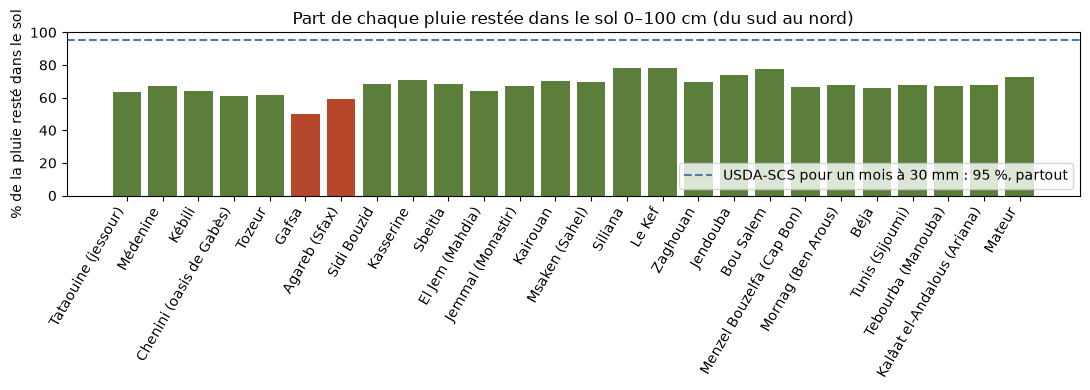

In [20]:
# 11b. Ce que disent les données : la part retenue change selon le site
g = ep[ASSEZ].groupby("site")[["pe_mesuree", "pluie_evt"]].sum()
part = g.pe_mesuree / g.pluie_evt
ordre = SITES.set_index("id").loc[part.index].sort_values("lat").index
part = part[ordre]
noms = SITES.set_index("id").nom
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar([noms[s] for s in part.index], part * 100, color=["#b7472a" if v < 0.6 else "#5b7f3a" for v in part])
ax.axhline(95, ls="--", color="#4a7bb7", label="USDA-SCS pour un mois à 30 mm : 95 %, partout")
ax.set_ylabel("% de la pluie resté dans le sol"); ax.set_ylim(0, 100); ax.legend(loc="lower right")
ax.set_title("Part de chaque pluie restée dans le sol 0–100 cm (du sud au nord)")
plt.xticks(rotation=60, ha="right"); fig.tight_layout()

In [21]:
# 11c. Entraînement
EP_ENT   = ASSEZ & ~ep.test_geo & (ep.annee <= FIN_ENTRAIN)
EP_VALID = ASSEZ & ~ep.test_geo & (ep.annee == ANNEE_VALID)
EP_TESTS = {"années jamais vues": ASSEZ & ~ep.test_geo & (ep.annee >= DEBUT_TEST),
            "lieux jamais vus":   ASSEZ &  ep.test_geo & (ep.annee >= DEBUT_TEST)}

modele_pe = lgb.LGBMRegressor(n_estimators=4000, learning_rate=0.02, num_leaves=15, min_child_samples=30, objective="l1",
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
modele_pe.fit(ep.loc[EP_ENT, VARIABLES_PE], ep.loc[EP_ENT, "pe_mesuree"],
              eval_set=[(ep.loc[EP_VALID, VARIABLES_PE], ep.loc[EP_VALID, "pe_mesuree"])],
              callbacks=[lgb.early_stopping(200, verbose=False)])
print(f"Entraîné sur {EP_ENT.sum()} épisodes ({modele_pe.best_iteration_} arbres)")

def pe_modele(t):
    return np.clip(modele_pe.predict(t[VARIABLES_PE]), 0, t.pluie_evt)

def usda_scs(p):
    p = np.asarray(p, dtype=float)
    return np.where(p <= 250, p * (125 - 0.2 * p) / 125, 125 + 0.1 * p)

frac_moy = ep[EP_ENT].pe_mesuree.sum() / ep[EP_ENT].pluie_evt.sum()
g = ep[EP_ENT].groupby("site")[["pe_mesuree", "pluie_evt"]].sum()
frac_site = g.pe_mesuree / g.pluie_evt

Entraîné sur 1496 épisodes (187 arbres)


### Évaluation par épisode de pluie
Cinq façons d'estimer la pluie efficace d'un épisode, comparées à ce que le sol a vraiment gardé :
- **USDA-SCS** : la formule actuelle de la page Eau & énergie ;
- **Règle 80 %** : la règle journalière de la page Ma ferme (0 sous 5 mm, sinon 80 %) ;
- **Fraction moyenne** : une seule part fixe, apprise sur toutes les données d'entraînement ;
- **Moyenne du site** : la part moyenne de ce site (pour un lieu jamais vu : la moyenne générale) ;
- **Modèle GAIA**.

**MAE** = erreur moyenne en mm par épisode ; **biais** > 0 = surestime l'eau apportée par la pluie, donc sous-estime l'irrigation.

In [22]:
# 11d. Évaluation par épisode
lignes = []
for nom, masque in EP_TESTS.items():
    te = ep[masque]; P, vrai = te.pluie_evt, te.pe_mesuree
    estim = {"USDA-SCS (formule actuelle)": usda_scs(P),
             "Règle 80 % (> 5 mm)": np.where(P >= 5, 0.8 * P, 0),
             "Fraction moyenne": P * frac_moy,
             "Moyenne du site": P * te.site.map(frac_site).fillna(frac_moy),
             "Modèle GAIA": pe_modele(te)}
    for methode, e in estim.items():
        err = np.asarray(e) - vrai
        lignes.append(dict(test=nom, methode=methode, episodes=len(te), MAE_mm=np.abs(err).mean(), biais_mm=err.mean(),
                           R2=1 - (err ** 2).sum() / ((vrai - vrai.mean()) ** 2).sum()))
eval_pe = pd.DataFrame(lignes)
display(eval_pe.pivot(index="methode", columns="test", values=["MAE_mm", "biais_mm", "R2"]).round(2))
for nom in EP_TESTS:
    r = eval_pe[eval_pe.test == nom].set_index("methode").MAE_mm
    print(f"{nom:20s} erreur du modèle : {1 - r['Modèle GAIA'] / r['USDA-SCS (formule actuelle)']:.0%} de moins que USDA-SCS, "
          f"{1 - r['Modèle GAIA'] / r['Fraction moyenne']:.0%} de moins qu'une fraction fixe")

MAE_mm                   \
test                        années jamais vues lieux jamais vus   
methode                                                           
Fraction moyenne                          4.08             3.21   
Modèle GAIA                               3.67             3.06   
Moyenne du site                           4.08             3.21   
Règle 80 % (> 5 mm)                       4.32             3.31   
USDA-SCS (formule actuelle)               4.53             3.15   

                                      biais_mm                   \
test                        années jamais vues lieux jamais vus   
methode                                                           
Fraction moyenne                          1.22             0.04   
Modèle GAIA                               0.81            -0.11   
Moyenne du site                           1.14             0.04   
Règle 80 % (> 5 mm)                       1.40            -0.06   
USDA-SCS (formule actuelle)               4.29             2.74   

                                            R2                   
test                        années jamais vues lieux jamais vus  
methode                                                          
Fraction moyenne                          0.48             0.81  
Modèle GAIA                               0.66             0.81  
Moyenne du site                           0.46             0.81  
Règle 80 % (> 5 mm)                       0.36             0.81  
USDA-SCS (formule actuelle)               0.18             0.77

années jamais vues   erreur du modèle : 19% de moins que USDA-SCS, 10% de moins qu'une fraction fixe
lieux jamais vus     erreur du modèle : 3% de moins que USDA-SCS, 4% de moins qu'une fraction fixe


### Évaluation par mois : ce que voit le calcul Eau & énergie
La page Eau & énergie travaille au **mois**. Pour chaque site et chaque mois de test, on additionne la pluie efficace mesurée des épisodes, puis on compare à la formule USDA-SCS appliquée à la pluie du mois et au modèle GAIA (somme de ses prédictions).

In [23]:
# 11e. Évaluation par mois (somme des épisodes)
tous = ep[ep.annee >= DEBUT_TEST].copy()
tous["pe_gaia"] = pe_modele(tous)
tous["mois"] = tous.debut.dt.to_period("M")
pluie_mois = pe_data.assign(mois=pe_data.date.dt.to_period("M")).groupby(["site", "mois"]).pluie.sum()
mensuel = tous.groupby(["site", "mois"]).agg(pe_mesuree=("pe_mesuree", "sum"), pe_gaia=("pe_gaia", "sum")).reindex(pluie_mois.index).fillna(0)
mensuel["pluie"] = pluie_mois
mensuel = mensuel[mensuel.index.get_level_values("mois").year >= DEBUT_TEST].reset_index()
mensuel = mensuel[mensuel.pluie >= 5]                                     # mois avec de la pluie
mensuel["usda"] = usda_scs(mensuel.pluie)
mensuel["test_geo"] = mensuel.site.map(SITES.set_index("id").test_geo)
lignes = []
for nom, m in [("années jamais vues", ~mensuel.test_geo), ("lieux jamais vus", mensuel.test_geo)]:
    t = mensuel[m]
    for methode, col in [("USDA-SCS (formule actuelle)", "usda"), ("Modèle GAIA", "pe_gaia")]:
        err = t[col] - t.pe_mesuree
        lignes.append(dict(test=nom, methode=methode, mois=len(t), MAE_mm_par_mois=np.abs(err).mean(), biais_mm_par_mois=err.mean(),
                           part_efficace=t[col].sum() / t.pluie.sum()))
    lignes.append(dict(test=nom, methode="Mesuré dans le sol", mois=len(t), MAE_mm_par_mois=0.0, biais_mm_par_mois=0.0,
                       part_efficace=t.pe_mesuree.sum() / t.pluie.sum()))
eval_mois = pd.DataFrame(lignes)
display(eval_mois.round(2))

,test,methode,mois,MAE_mm_par_mois,biais_mm_par_mois,part_efficace
0,années jamais vues,USDA-SCS (formule actuelle),389,12.05,11.22,0.90
1,années jamais vues,Modèle GAIA,389,6.35,3.03,0.68
2,années jamais vues,Mesuré dans le sol,389,0.00,0.00,0.60
3,lieux jamais vus,USDA-SCS (formule actuelle),68,9.86,8.17,0.93
4,lieux jamais vus,Modèle GAIA,68,5.24,0.91,0.69
5,lieux jamais vus,Mesuré dans le sol,68,0.00,0.00,0.67


### Les coefficients mensuels pour la page Eau & énergie
Comme pour l'humidité, le modèle est ensuite **réentraîné sur tous les épisodes, de 2020 à hier, sur les 26 sites** (mêmes réglages). Ce modèle final est appliqué à **tous les épisodes de pluie de 2020 à hier** de chaque site. Pour chaque mois de l'année :
**part efficace = Σ pluie efficace prédite / Σ pluie tombée** (les pluies de moins de 1 mm comptent comme non efficaces).
Quand un mois a trop peu de pluie sur la période (moins de 15 mm au total), on prend la part annuelle du site.
La page multiplie la pluie mensuelle du profil de la parcelle par la part du **site d'entraînement le plus proche**.

Modèle final : 3415 épisodes, 26 sites, 05/02/2020 → 15/11/2026


{
 "années jamais vues": {
  "mae_episode_gaia": 3.67,
  "mae_episode_usda": 4.53,
  "mae_episode_fraction_fixe": 4.08,
  "mae_mois_gaia": 6.3,
  "mae_mois_usda": 12.0,
  "part_mesuree": 0.6,
  "part_usda": 0.902
 },
 "lieux jamais vus": {
  "mae_episode_gaia": 3.06,
  "mae_episode_usda": 3.15,
  "mae_episode_fraction_fixe": 3.21,
  "mae_mois_gaia": 5.2,
  "mae_mois_usda": 9.9,
  "part_mesuree": 0.666,
  "part_usda": 0.926
 }
}


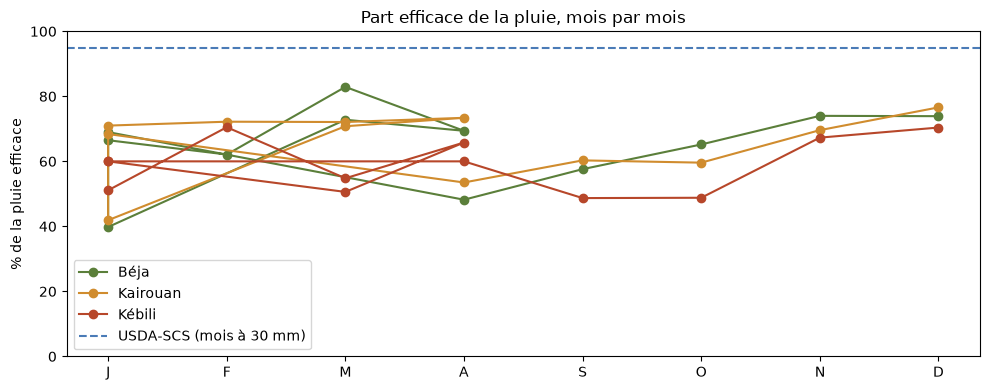

In [24]:
# 11f. Modèle final (tous les sites, 2020 → hier), coefficients mensuels par site, sauvegarde
EP_TOUT = ep.pluie_evt >= 3
modele_pe_final = lgb.LGBMRegressor(**{**modele_pe.get_params(), "n_estimators": modele_pe.best_iteration_})
modele_pe_final.fit(ep.loc[EP_TOUT, VARIABLES_PE], ep.loc[EP_TOUT, "pe_mesuree"])
print(f"Modèle final : {EP_TOUT.sum()} épisodes, {ep[EP_TOUT].site.nunique()} sites, "
      f"{ep[EP_TOUT].debut.min():%d/%m/%Y} → {ep[EP_TOUT].debut.max():%d/%m/%Y}")
ep["pe_gaia"] = np.clip(modele_pe_final.predict(ep[VARIABLES_PE]), 0, ep.pluie_evt)
ep["mois"] = ep.debut.dt.month
pluie_tot = pe_data.groupby(["site", pe_data.date.dt.month]).pluie.sum()
pe_tot = ep.groupby(["site", "mois"]).pe_gaia.sum()
annees = (pe_data.date.max() - pe_data.date.min()).days / 365.25
coef = {}
for s in SITES.itertuples():
    if s.id not in pluie_tot.index.get_level_values(0):
        continue
    annuel = pe_tot.get(s.id, pd.Series(dtype=float)).sum() / pluie_tot[s.id].sum()
    parts = []
    for m in range(1, 13):
        p, e = pluie_tot.get((s.id, m), 0.0), pe_tot.get((s.id, m), 0.0)
        parts.append(round(float(e / p if p >= 15 else annuel), 3))
    coef[s.id] = dict(nom=s.nom, lat=s.lat, lon=s.lon, part_mensuelle=parts, part_annuelle=round(float(annuel), 3),
                      pluie_mm_par_an=round(float(pluie_tot[s.id].sum() / annees)))

fig, ax = plt.subplots(figsize=(10, 4))
mois_noms = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
for sid, c in [("beja", "#5b7f3a"), ("kairouan", "#d08c2e"), ("kebili", "#b7472a")]:
    ax.plot(mois_noms, np.array(coef[sid]["part_mensuelle"]) * 100, "o-", color=c, label=coef[sid]["nom"])
ax.axhline(95, ls="--", color="#4a7bb7", label="USDA-SCS (mois à 30 mm)")
ax.set_ylim(0, 100); ax.set_ylabel("% de la pluie efficace"); ax.legend(); ax.set_title("Part efficace de la pluie, mois par mois")
fig.tight_layout()

modele_pe_final.booster_.save_model(str(MODEL_DIR / "pluie_efficace.txt"))
r_ep = eval_pe.set_index(["test", "methode"])
r_mo = eval_mois.set_index(["test", "methode"])
resume = {t: dict(mae_episode_gaia=round(r_ep.loc[(t, "Modèle GAIA"), "MAE_mm"], 2),
                  mae_episode_usda=round(r_ep.loc[(t, "USDA-SCS (formule actuelle)"), "MAE_mm"], 2),
                  mae_episode_fraction_fixe=round(r_ep.loc[(t, "Fraction moyenne"), "MAE_mm"], 2),
                  mae_mois_gaia=round(r_mo.loc[(t, "Modèle GAIA"), "MAE_mm_par_mois"], 1),
                  mae_mois_usda=round(r_mo.loc[(t, "USDA-SCS (formule actuelle)"), "MAE_mm_par_mois"], 1),
                  part_mesuree=round(r_mo.loc[(t, "Mesuré dans le sol"), "part_efficace"], 3),
                  part_usda=round(r_mo.loc[(t, "USDA-SCS (formule actuelle)"), "part_efficace"], 3))
          for t in EP_TESTS}
meta_pe = dict(
    cible="pluie efficace d'un épisode (mm) = gain d'eau du sol 0–100 cm + séchage attendu, bornée à la pluie",
    source="Open-Meteo, ECMWF IFS", periode=f"{START} → {END}", variables=VARIABLES_PE,
    decoupage=dict(entrainement=f"2020–{FIN_ENTRAIN}", validation=str(ANNEE_VALID), test=f"{DEBUT_TEST} → {END}",
                   lieux_jamais_vus=SITES[SITES.test_geo].id.tolist()),
    modele_final=dict(entraine_sur=f"{ep[EP_TOUT].debut.min():%Y-%m-%d} → {ep[EP_TOUT].debut.max():%Y-%m-%d}", episodes=int(EP_TOUT.sum()),
                      sites=int(ep[EP_TOUT].site.nunique()),
                      note="scores mesurés avant, sur un modèle qui n'avait vu ni 2024–2026 ni les sites de test"),
    resultats=resume, sites=coef)
(MODEL_DIR / "pluie_efficace_meta.json").write_text(json.dumps(meta_pe, ensure_ascii=False, indent=1), encoding="utf-8")
print(json.dumps(resume, ensure_ascii=False, indent=1))

## Ce qu'il faut retenir
- Le modèle a **appris à partir des données 2020 → hier (ECMWF IFS, une seule source) sur 26 sites couvrant les 24 gouvernorats**. Il est testé sur **2025–2026**, les années les plus récentes, et sur 4 **lieux** qu'il n'a jamais vus. En direct, il part d'hier et couvre aujourd'hui + 7 jours.
- **Humidité du sol (section 9) :** il prévoit **environ la moitié des variations** de l'humidité (R² de la variation ≈ 0,36 à 0,51 selon le test et l'horizon), avec une erreur moyenne de **≈ 2,3 mm d'eau à J+7**, et **23 à 28 % d'erreur en moins** que la persistance. Le R² de l'humidité (≈ 0,96) est flatteur : la persistance atteint déjà ≈ 0,9.
- **Décision « irriguer » (section 9) :** ≈ 90–93 % de F1, mais la persistance fait aussi bien, car un sol sec reste sec longtemps.
- **Moments de bascule (section 10) :** c'est là que le modèle fait la différence. La persistance n'en annonce aucun ; le modèle en annonce **environ la moitié** (F1 ≈ 49–53 %, contre 25–40 % pour la tendance), **une fois sur deux au bon jour à ±1 jour**, avec un léger retard moyen (≈ 0,7 jour). Le modèle dédié aux bascules fait à peu près pareil que la trajectoire des modèles.
- **Pourquoi ces chiffres sont plus bas qu'une version précédente :** celle-ci mélangeait deux sources (ERA5-Land jusqu'en 2016, ECMWF IFS ensuite) et testait sur des années plus anciennes. Celle-ci utilise une seule source, la même qu'en direct, et teste sur les années les plus récentes : les chiffres sont plus modestes mais plus fiables.
- **Pluie efficace (section 11) :** dans le sol, il reste en moyenne **60 à 67 %** de la pluie ; la formule USDA-SCS en compte **≈ 90 %**. Le modèle divise par deux l'erreur mensuelle (**6,3 / 5,2 mm par mois** contre **12,0 / 9,9 mm** pour USDA-SCS, années / lieux jamais vus). Par épisode de pluie, le gain est plus modeste (−19 % d'erreur sur les années jamais vues, −3 % sur les lieux jamais vus) : l'essentiel vient de ce que la formule surestime toute pluie. Ses coefficients mensuels par site alimentent la page Eau & énergie.
- **Pistes d'amélioration :** ajouter les propriétés du sol SoilGrids ; vérifier avec l'humidité satellite **NASA SMAP** ; affiner sur une parcelle avec le **capteur de sol** (Kaizen) ; remplacer le seuil de 30 % par les seuils FAO-56 de la culture ; corriger le léger retard des bascules (annoncer un jour plus tôt quand la probabilité est élevée).